# EDA - Avis clients Revolut

Analyse exploratoire du dataset harmonisé (`data/processed/revolut_reviews.csv`), construit en combinant trois sources scrapées (Google Play Store, Apple App Store, Sitejabber).

**Objectifs de ce notebook :**
- Statistiques descriptives et qualité des données (valeurs manquantes, doublons résiduels)
- Distribution de la variable cible (note 1-5) et déséquilibre de classes
- Répartition par source et par langue
- Longueur des avis et lien avec la note
- Évolution temporelle du volume et du sentiment moyen
- Premier aperçu lexical (mots fréquents par polarité)
- Synthèse : pistes pour le prétraitement NLP (Étape 3)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

DATA_PATH = "../data/processed/revolut_reviews.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["date"], low_memory=False)
df.shape


(99493, 8)

## 1. Vue d'ensemble

In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99493 entries, 0 to 99492
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        99493 non-null  str           
 1   source    99493 non-null  str           
 2   rating    99493 non-null  int64         
 3   title     3531 non-null   str           
 4   text      99493 non-null  str           
 5   date      99493 non-null  datetime64[us]
 6   language  99493 non-null  str           
 7   country   3477 non-null   str           
dtypes: datetime64[us](1), int64(1), str(6)
memory usage: 17.3 MB


In [3]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(1)
missing


,missing_count,missing_pct
id,0,0.0
source,0,0.0
rating,0,0.0
title,95962,96.5
text,0,0.0
date,0,0.0
language,0,0.0
country,96016,96.5


`title` et `country` sont majoritairement vides par construction : seuls l'App Store et Sitejabber fournissent un titre, et seul l'App Store fournit un pays fiable (le `country` de Play Store a été écarté lors de l'harmonisation car il ne reflète pas la vraie localisation du reviewer, voir `src/data/build_dataset.py`). Ce n'est pas une anomalie à corriger.

In [4]:
duplicate_text_rating = df.duplicated(subset=["text", "rating"]).sum()
print(f"Lignes avec texte+note identiques à une autre ligne : {duplicate_text_rating} ({duplicate_text_rating/len(df)*100:.1f}%)")
print("Ce ne sont pas de vrais doublons : ce sont des avis génériques courts (\"super\", \"ok\", \"top\")")
print("écrits par des milliers d'utilisateurs distincts. Vérifié en Étape 2 (build_dataset.py) :")
print("aucune ligne ne partage texte+note+date+source à l'identique après nettoyage.")


Lignes avec texte+note identiques à une autre ligne : 28242 (28.4%)
Ce ne sont pas de vrais doublons : ce sont des avis génériques courts ("super", "ok", "top")
écrits par des milliers d'utilisateurs distincts. Vérifié en Étape 2 (build_dataset.py) :
aucune ligne ne partage texte+note+date+source à l'identique après nettoyage.


## 2. Distribution de la note (variable cible)

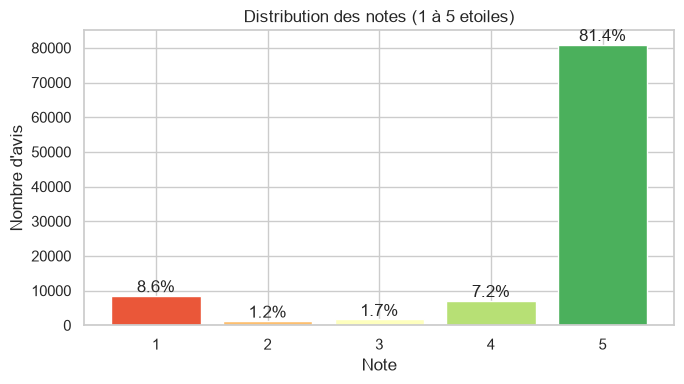

rating
1     8.6
2     1.2
3     1.7
4     7.2
5    81.4
Name: count, dtype: float64

In [5]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rating_counts.index, rating_counts.values, color=sns.color_palette("RdYlGn", 5))
for bar, pct in zip(bars, rating_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{pct}%",
            ha="center", va="bottom")
ax.set_xlabel("Note")
ax.set_ylabel("Nombre d'avis")
ax.set_title("Distribution des notes (1 à 5 etoiles)")
plt.tight_layout()
plt.show()

rating_pct


**Fort déséquilibre de classes** : ~81% des avis sont 5 étoiles, contre ~9% à 1 étoile et seulement 1-2% pour les notes intermédiaires (2, 3). C'est un déséquilibre typique des avis d'app stores (les utilisateurs très satisfaits ou très mécontents sont plus enclins à laisser un avis).

**Conséquence pour la modélisation (Étape 4)** : un modèle entraîné naïvement sur les 5 classes brutes prédira presque toujours "5 étoiles" et obtiendra une accuracy trompeusement haute. Il faudra soit :
- regrouper en classes de sentiment (ex. négatif = 1-2, neutre = 3, positif = 4-5, ou binaire négatif/positif en écartant la note 3),
- et/ou utiliser des métriques adaptées au déséquilibre (F1 macro, matrice de confusion) plutôt que l'accuracy seule,
- et/ou ré-échantillonner (sous-échantillonnage de la classe 5, ou pondération des classes).

Exploration de la version "sentiment 3 classes" ci-dessous :

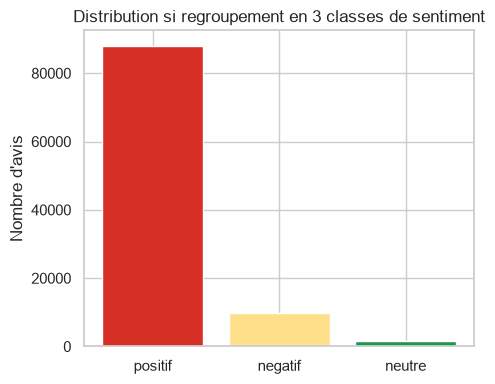

rating
positif    88.5
negatif     9.8
neutre      1.7
Name: count, dtype: float64

In [6]:
def to_sentiment(rating: int) -> str:
    if rating <= 2:
        return "negatif"
    if rating == 3:
        return "neutre"
    return "positif"

sentiment_counts = df["rating"].apply(to_sentiment).value_counts()
sentiment_pct = (sentiment_counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(sentiment_counts.index, sentiment_counts.values,
       color=["#d73027", "#fee08b", "#1a9850"])
ax.set_ylabel("Nombre d'avis")
ax.set_title("Distribution si regroupement en 3 classes de sentiment")
plt.tight_layout()
plt.show()

sentiment_pct


## 3. Répartition par source et par langue

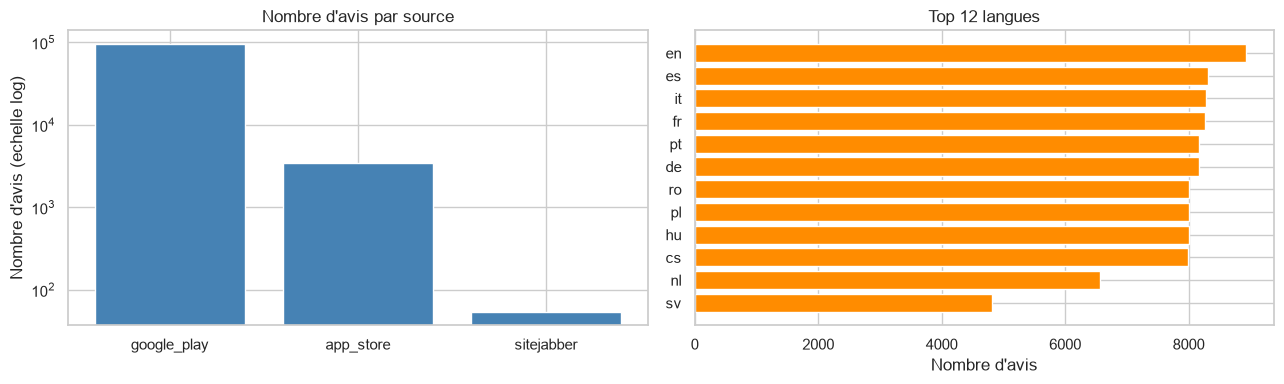

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

source_counts = df["source"].value_counts()
axes[0].bar(source_counts.index, source_counts.values, color="steelblue")
axes[0].set_title("Nombre d'avis par source")
axes[0].set_yscale("log")
axes[0].set_ylabel("Nombre d'avis (echelle log)")

lang_counts = df["language"].value_counts().head(12)
axes[1].barh(lang_counts.index[::-1], lang_counts.values[::-1], color="darkorange")
axes[1].set_title("Top 12 langues")
axes[1].set_xlabel("Nombre d'avis")

plt.tight_layout()
plt.show()


Le dataset est très largement dominé par Google Play (>95%), l'App Store et Sitejabber n'apportant qu'un complément qualitatif marginal en volume. Cela signifie que les conclusions statistiques globales seront essentiellement portées par Play Store ; toute analyse par source devra interpréter App Store/Sitejabber avec prudence (effectifs faibles).

In [8]:
avg_rating_by_source = df.groupby("source")["rating"].agg(["mean", "count"]).round(2)
avg_rating_by_source


,mean,count
source,,
app_store,4.82,3477
google_play,4.51,95962
sitejabber,1.57,54


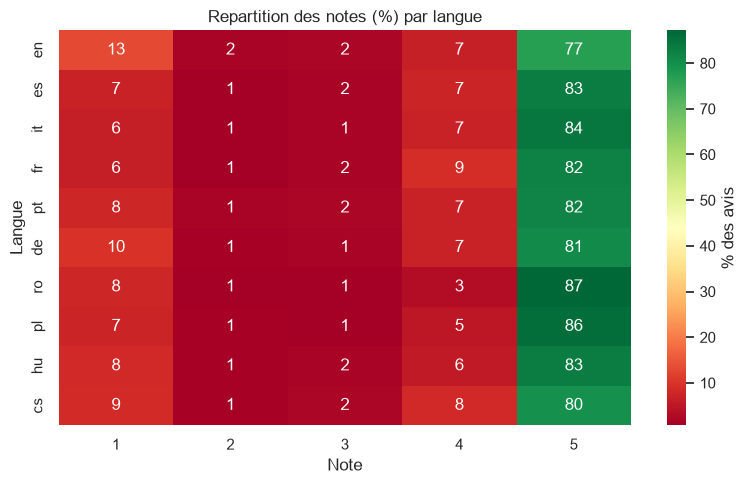

In [9]:
top_languages = df["language"].value_counts().head(10).index
pivot = (
    df[df["language"].isin(top_languages)]
    .pivot_table(index="language", columns="rating", values="id", aggfunc="count", fill_value=0)
)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_pct.loc[top_languages], annot=True, fmt=".0f", cmap="RdYlGn", cbar_kws={"label": "% des avis"}, ax=ax)
ax.set_title("Repartition des notes (%) par langue")
ax.set_xlabel("Note")
ax.set_ylabel("Langue")
plt.tight_layout()
plt.show()


## 4. Longueur des avis

In [10]:
df["char_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

df[["char_length", "word_count"]].describe()


,char_length,word_count
count,99493.000000,99493.000000
mean,55.220066,9.317299
std,90.701661,15.369777
min,1.000000,1.000000
25%,9.000000,2.000000
50%,22.000000,4.000000
75%,59.000000,10.000000
max,3549.000000,657.000000


C:\Users\charl\AppData\Local\Temp\ipykernel_27616\3617984894.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="rating", y="char_length", ax=axes[1], showfliers=False, palette="RdYlGn")


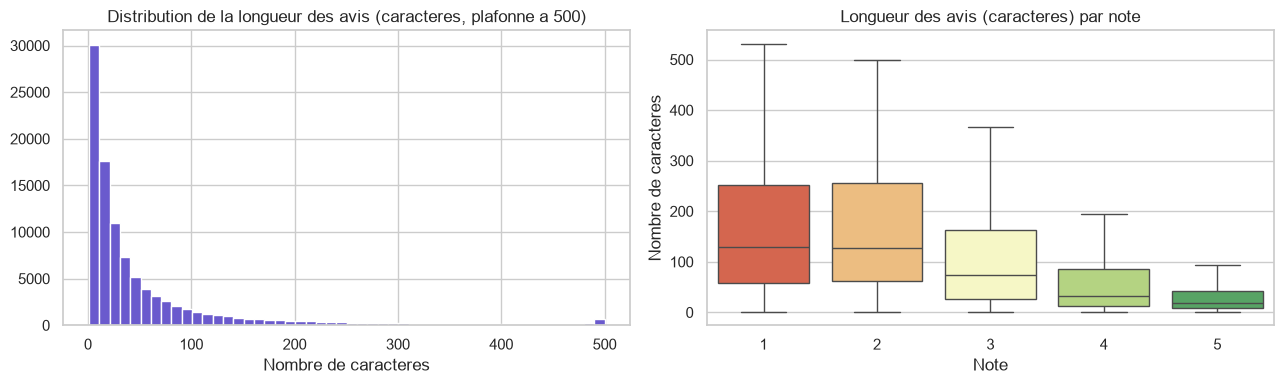

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["char_length"].clip(upper=500), bins=50, color="slateblue")
axes[0].set_title("Distribution de la longueur des avis (caracteres, plafonne a 500)")
axes[0].set_xlabel("Nombre de caracteres")

sns.boxplot(data=df, x="rating", y="char_length", ax=axes[1], showfliers=False, palette="RdYlGn")
axes[1].set_title("Longueur des avis (caracteres) par note")
axes[1].set_xlabel("Note")
axes[1].set_ylabel("Nombre de caracteres")

plt.tight_layout()
plt.show()


Les avis très courts (1-3 mots : "super", "ok", "top") sont fréquents, surtout pour les notes 4-5. Les avis négatifs (1-2 étoiles) ont tendance à être plus longs en médiane : les utilisateurs mécontents détaillent davantage leur problème. C'est un signal exploitable pour la classification, mais cela veut aussi dire qu'un grand nombre d'avis positifs très courts porteront peu d'information lexicale (à garder en tête pour le choix du vectoriseur en Étape 4 : TF-IDF sur unigrammes seuls risque d'être peu discriminant sur ces avis).

## 5. Evolution temporelle

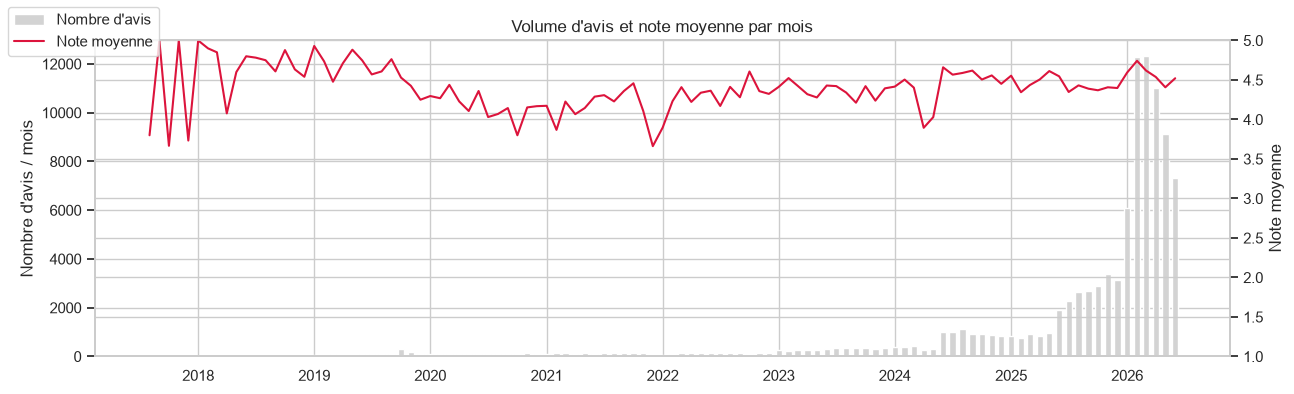

In [12]:
monthly = df.set_index("date").resample("MS").agg(count=("rating", "size"), avg_rating=("rating", "mean"))
monthly = monthly[monthly["count"] >= 5]  # mois avec trop peu d'avis sont peu fiables pour la moyenne

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(monthly.index, monthly["count"], width=20, color="lightgray", label="Nombre d'avis")
ax1.set_ylabel("Nombre d'avis / mois")

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["avg_rating"], color="crimson", label="Note moyenne")
ax2.set_ylabel("Note moyenne")
ax2.set_ylim(1, 5)

ax1.set_title("Volume d'avis et note moyenne par mois")
fig.legend(loc="upper left")
plt.tight_layout()
plt.show()


Le volume d'avis croît fortement avec le temps (croissance de l'usage de l'app), donc les années récentes domineront statistiquement le dataset. La note moyenne mensuelle permet de repérer d'éventuels incidents (chutes brutales) qui pourraient corréler avec des évènements produits (pannes, changements de CGU, etc.) — utile pour contextualiser les avis négatifs en analyse qualitative.

## 6. Apercu lexical (mots frequents par polarite)

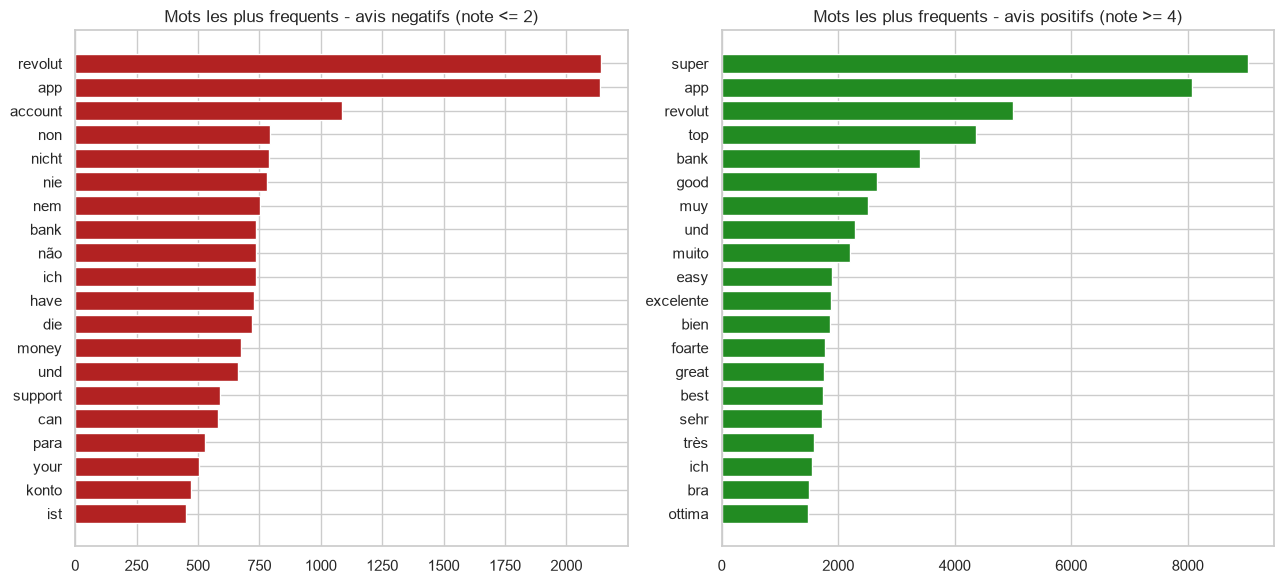

In [13]:
import re
from collections import Counter

FR_EN_STOPWORDS = set('''
le la les un une des de du et a au aux ce cette ces il elle ils elles je tu nous vous on
que qui quoi est sont pas ne plus tres pour avec sur dans par mais ou donc car the a an
and or but for with on in to is are was were this that i you he she it we they of not very
'''.split())

def top_words(texts: pd.Series, n: int = 20) -> list[tuple[str, int]]:
    counter: Counter[str] = Counter()
    for text in texts.dropna():
        tokens = re.findall(r"[a-zA-Zà-üÀ-Ü]+", text.lower())
        counter.update(t for t in tokens if t not in FR_EN_STOPWORDS and len(t) > 2)
    return counter.most_common(n)

negative_words = top_words(df.loc[df["rating"] <= 2, "text"])
positive_words = top_words(df.loc[df["rating"] >= 4, "text"])

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh([w for w, _ in negative_words[::-1]], [c for _, c in negative_words[::-1]], color="firebrick")
axes[0].set_title("Mots les plus frequents - avis negatifs (note <= 2)")
axes[1].barh([w for w, _ in positive_words[::-1]], [c for _, c in positive_words[::-1]], color="forestgreen")
axes[1].set_title("Mots les plus frequents - avis positifs (note >= 4)")
plt.tight_layout()
plt.show()


Ceci est une analyse lexicale très grossière (regex simple + minuscule + une petite liste de mots vides FR/EN écrite à la main), volontairement limitée : la vraie tokenisation/lemmatisation multilingue (spaCy, gestion des emojis, mots vides par langue) est le cœur de l'**Étape 3**. L'objectif ici est juste de confirmer que le signal lexical attendu (mots liés au service client, à l'argent, vs mots élogieux génériques) est bien présent avant d'investir dans un pipeline NLP complet.

## 7. Synthese - pistes pour le pretraitement (Etape 3)

**Constats de cette EDA :**
1. **Déséquilibre fort des classes** (81% de 5 étoiles) → décider d'un mapping note→sentiment (binaire ou 3 classes) et/ou d'une stratégie de rééquilibrage avant modélisation.
2. **Multilinguisme réel** (15 langues, dominées par en/es/it/fr/pt/de) → la tokenisation/lemmatisation devra être spécifique à la langue (spaCy a des modèles par langue), ou alors restreindre le périmètre de modélisation à 1-2 langues pour limiter l'effort (à valider).
3. **Beaucoup d'avis très courts** (1-3 mots) → peu de signal lexical pour ces lignes ; envisager de les garder mais ne pas s'attendre à une performance élevée du modèle sur ce sous-ensemble.
4. **`unknown` en langue** pour 1282 avis (App Store/Sitejabber, texte trop court pour une détection fiable) → décider de les exclure du pipeline NLP multilingue, ou de les traiter comme un pot commun FR/EN par défaut.
5. **Volume très déséquilibré entre sources** (96k Play Store vs 3.5k App Store vs 54 Sitejabber) → toute comparaison "par source" doit rester prudente sur les petits effectifs.
6. **Aucune valeur manquante critique** sur `text`/`rating`/`date` après nettoyage (Étape 2) : le dataset est sain, pas de travail d'imputation nécessaire.

**Décision à valider avec l'utilisateur avant l'Étape 3** : périmètre linguistique du pipeline NLP (toutes les 15 langues vs un sous-ensemble), et mapping note→sentiment retenu pour la modélisation.